# Baseline: TF-IDF + Logistic Regression (BANKING77)

Three feature sets with the same classifier, compared on the validation set. The official test set is not touched here: it is used once, for the final model.

In [11]:
import random
import string

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import FeatureUnion, Pipeline

pd.set_option("display.max_colwidth", 120)

In [12]:
# The MLflow server must be running in a separate terminal
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("banking77-intents")

<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1793054079920, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1793095863688, lifecycle_stage='active', name='banking77-intents', tags={}, trace_location=None, workspace='default'>

In [13]:
train = pd.read_csv("../data/processed/train.csv")
val = pd.read_csv("../data/processed/val.csv")

X_train, y_train = train["text"], train["intent"]
X_val, y_val = val["text"], val["intent"]
print(f"train={len(train)} val={len(val)} intents={y_train.nunique()}")

train=3379 val=1492 intents=77


## How close is validation to train?

Share of validation requests with a near-duplicate in train (TF-IDF cosine). On Bitext this was 29.5% at ≥ 0.8.

In [14]:
vec = TfidfVectorizer(ngram_range=(1, 2)).fit(X_train)
nn = NearestNeighbors(n_neighbors=1, metric="cosine").fit(vec.transform(X_train))
dist, _ = nn.kneighbors(vec.transform(X_val))
sim = 1 - dist[:, 0]
for t in [0.8, 0.9, 0.95]:
    print(f"val texts with a train neighbour at cosine >= {t}: {(sim >= t).mean():.1%}")

val texts with a train neighbour at cosine >= 0.8: 6.0%
val texts with a train neighbour at cosine >= 0.9: 1.5%
val texts with a train neighbour at cosine >= 0.95: 0.3%


## Feature sets

- **word**: word unigrams + bigrams
- **char**: character 2–5-grams inside word boundaries (robust to typos)
- **word+char**: both, concatenated

In [15]:
def word_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)


def char_tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)


feature_sets = {
    "word": word_tfidf(),
    "char": char_tfidf(),
    "word+char": FeatureUnion([("word", word_tfidf()), ("char", char_tfidf())]),
}

## Training

One MLflow run per feature set: parameters, validation metrics and the fitted pipeline.

In [16]:
results, models = {}, {}
for name, features in feature_sets.items():
    with mlflow.start_run(run_name=f"baseline_logreg_{name}"):
        model = Pipeline([("features", features), ("clf", LogisticRegression(max_iter=3000))])
        model.fit(X_train, y_train)
        pred = model.predict(X_val)
        metrics = {
            "macro_f1": f1_score(y_val, pred, average="macro"),
            "accuracy": accuracy_score(y_val, pred),
        }

        mlflow.set_tag("stage", "baseline")
        mlflow.log_params(
            {"model": "logreg", "features": name, "C": 1.0, "train_rows": len(train)}
        )
        mlflow.log_metrics({f"val_{k}": v for k, v in metrics.items()})
        mlflow.sklearn.log_model(model, name="model")

    results[name], models[name] = metrics, model

results = pd.DataFrame(results).T.rename_axis("features").round(4)
results

🏃 View run baseline_logreg_word at: http://127.0.0.1:5000/#/experiments/2/runs/6c3cd5bb7c5348439f94541ce4d0fb11
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run baseline_logreg_char at: http://127.0.0.1:5000/#/experiments/2/runs/8e8e2fbe7bb24df0917563fcca6a4596
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run baseline_logreg_word+char at: http://127.0.0.1:5000/#/experiments/2/runs/ef44521c59a94112b84313c634409221
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


,macro_f1,accuracy
features,,
word,0.7696,0.7882
char,0.7966,0.8103
word+char,0.8299,0.8405


## Error analysis

Most frequent confusions of the best feature set on the validation set.

In [17]:
best_name = results["macro_f1"].idxmax()
best = models[best_name]
pred = best.predict(X_val)

labels = sorted(y_val.unique())
cm = pd.DataFrame(confusion_matrix(y_val, pred, labels=labels), index=labels, columns=labels)
cm.index.name, cm.columns.name = "true", "pred"

pairs = cm.stack().rename("count").reset_index()
errors_only = (pairs["true"] != pairs["pred"]) & (pairs["count"] > 0)
print(f"Best feature set: {best_name}, errors: {int((pred != y_val).sum())} of {len(y_val)}")
pairs[errors_only].sort_values("count", ascending=False).head(15)

Best feature set: word+char, errors: 238 of 1492


,true,pred,count
4943,transfer_fee_charged,card_payment_fee_charged,7
5310,unable_to_verify_identity,why_verify_identity,5
2481,exchange_rate,card_payment_wrong_exchange_rate,4
5869,wrong_exchange_rate_for_cash_withdrawal,card_payment_wrong_exchange_rate,4
433,balance_not_updated_after_bank_transfer,pending_transfer,3
2572,exchange_via_app,exchange_charge,3
1978,declined_card_payment,reverted_card_payment,3
1939,declined_card_payment,card_not_working,3
2172,direct_debit_payment_not_recognised,card_payment_not_recognised,3
1385,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal,3


In [18]:
errors = val.assign(pred=pred).query("intent != pred")
errors[["instruction", "intent", "pred"]].sample(min(15, len(errors)), random_state=42)

,instruction,intent,pred
649,Does it cost me to add cash?,top_up_by_bank_transfer_charge,top_up_by_card_charge
74,I can't use my virtual disposable card,virtual_card_not_working,get_disposable_virtual_card
1323,A seller is stating that they haven't received money yet when the money has already deducted from my account.,reverted_card_payment,transfer_not_received_by_recipient
726,How long does it take for a new card to ship?,card_arrival,card_delivery_estimate
27,Can I use my card for online payments?,card_acceptance,declined_card_payment
1035,The card has suffered a security breach.,compromised_card,card_arrival
60,Is there a topping up limit?,top_up_limits,top_up_by_card_charge
1392,I added money to the card but the transaction didn't go through,pending_top_up,transfer_not_received_by_recipient
641,I have not been able to use this card.,card_not_working,card_payment_fee_charged
1386,Is there extra fees for making a withdraw in a different country at a cash machine.,wrong_exchange_rate_for_cash_withdrawal,cash_withdrawal_charge


About half of the inspected validation errors look like debatable labels rather than model mistakes (e.g. “How long does it take for a new card to ship?” is labelled card_arrival, the model predicts card_delivery_estimate). This matches Ying & Thomas (2022), who estimate that ~14% of BANKING77 training utterances may be mislabelled. Genuine model errors come from synonyms (“security breach” → should be compromised_card) and word forms (“topping up” vs. “top up”), which motivates char n-grams and a semantic model.

## Confidence-based routing

Predictions below a threshold go to a human agent. Intents that trigger irreversible actions always require confirmation; here we count how often they are predicted wrongly.

In [19]:
proba = best.predict_proba(X_val)
val_eval = val.assign(pred=pred, confidence=proba.max(axis=1), correct=pred == y_val.to_numpy())

rows = []
for t in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6]:
    auto = val_eval["confidence"] >= t
    rows.append({
        "threshold": t,
        "automated": auto.mean(),
        "accuracy_automated": val_eval.loc[auto, "correct"].mean() if auto.any() else float("nan"),
        "errors_automated": int((~val_eval.loc[auto, "correct"]).sum()),
    })
pd.DataFrame(rows).round(3)

,threshold,automated,accuracy_automated,errors_automated
0,0.0,1.000,0.840,238
1,0.2,0.750,0.929,79
2,0.3,0.599,0.956,39
3,0.4,0.475,0.972,20
4,0.5,0.350,0.983,9
5,0.6,0.233,1.000,0


In [20]:
RISKY = {"terminate_account", "cancel_transfer", "lost_or_stolen_card", "compromised_card"}
critical = val_eval[val_eval["pred"].isin(RISKY) & ~val_eval["correct"]]
print(f"Critical errors (risky intent predicted wrongly): {len(critical)}")
critical[["instruction", "intent", "pred", "confidence"]]

Critical errors (risky intent predicted wrongly): 10


,instruction,intent,pred,confidence
172,I was the victim of someone stealing my wallet. My card is being used and it isn't me. What should I do?,cash_withdrawal_not_recognised,compromised_card,0.074974
298,If my card was lost or stolen can I re-link it?,card_linking,lost_or_stolen_card,0.259956
571,Was my transaction reverted with my card?,reverted_card_payment,cancel_transfer,0.083875
602,What can I do if my card details where stolen from my car? I think they used my card to buy gas.,compromised_card,lost_or_stolen_card,0.102479
609,Why did the ATM cancel my transaction,declined_cash_withdrawal,cancel_transfer,0.515224
858,I would like to cancel my account.,terminate_account,cancel_transfer,0.220680
1039,I haven't been able to complete any transactions on my card today. Do you know what's wrong?,card_not_working,compromised_card,0.059416
1216,"I am seeing unathorized transactions in the app, on my account.",cash_withdrawal_not_recognised,compromised_card,0.080160
1273,I need my card immediately.,card_delivery_estimate,lost_or_stolen_card,0.119020
1490,You accepts my card?,card_acceptance,lost_or_stolen_card,0.101534


Confidence-based routing: at a threshold of 0.6 the TF-IDF router handles 23% of validation queries with no errors; at 0.4 it handles 47.5% with 97.2% accuracy. Low-confidence queries are passed to the LLM assistant (model cascade).
Error costs are asymmetric: predicting cancel_transfer or terminate_account by mistake triggers an irreversible action (often caused by the word “cancel”), so these intents always require user confirmation; predicting compromised_card by mistake leads at worst to a reversible card block.

## Robustness to synthetic typos

In [21]:
def add_typos(text: str, rate: float, rng: random.Random) -> str:
    """Corrupt letters in alphabetic words: delete, swap, replace or insert, each char with prob `rate`."""
    words = []
    for word in text.split():
        if not word.isalpha():  # keep <num> and punctuation
            words.append(word)
            continue
        chars, out, i = list(word), [], 0
        while i < len(chars):
            if rng.random() < rate:
                op = rng.choice(["delete", "swap", "replace", "insert"])
                if op == "delete":
                    i += 1
                    continue
                if op == "swap" and i + 1 < len(chars):
                    out += [chars[i + 1], chars[i]]
                    i += 2
                    continue
                if op == "replace":
                    out.append(rng.choice(string.ascii_lowercase))
                    i += 1
                    continue
                if op == "insert":
                    out += [chars[i], rng.choice(string.ascii_lowercase)]
                    i += 1
                    continue
            out.append(chars[i])
            i += 1
        if out:
            words.append("".join(out))
    return " ".join(words)


rng = random.Random(42)
rows = []
for rate in [0.0, 0.05, 0.1, 0.2, 0.3]:
    noisy = X_val.map(lambda t: add_typos(t, rate, rng))
    row = {"typo_rate": rate}
    for name, model in models.items():
        row[name] = f1_score(y_val, model.predict(noisy), average="macro")
    rows.append(row)

robust = pd.DataFrame(rows).set_index("typo_rate").round(4)
robust

,word,char,word+char
typo_rate,,,
0.00,0.7696,0.7966,0.8299
0.05,0.6813,0.7816,0.7978
0.10,0.6065,0.7559,0.7495
0.20,0.4727,0.6830,0.6684
0.30,0.4068,0.6088,0.5804


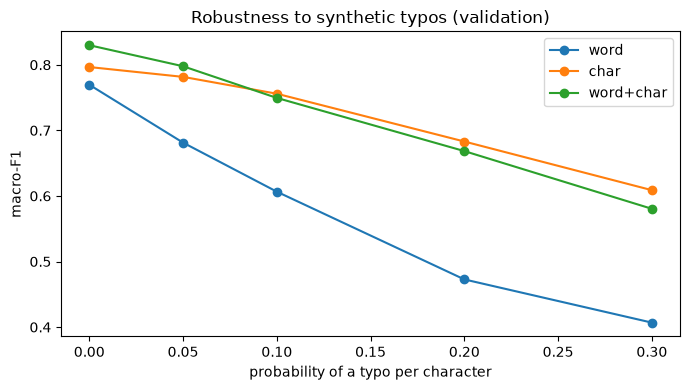

In [22]:
ax = robust.plot(marker="o", figsize=(7, 4), title="Robustness to synthetic typos (validation)")
ax.set_xlabel("probability of a typo per character")
ax.set_ylabel("macro-F1")
plt.tight_layout()
plt.show()

Robustness: word+char is best on clean text (macro-F1 0.83), but char n-grams are more robust from 10% character noise on (0.61 vs. 0.58 at 30%; word n-grams drop to 0.41).

In [23]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)
joblib.dump(models["word+char"], "../models/router.joblib")

['../models/router.joblib']